# Midterm: ZORI Rental Data Curation Pilot
**Cassy Cormier**
| October 10th, 2026

### **Overview**  
This pilot demonstrates a full data‑curation workflow using the **Zillow Observed Rent Index (ZORI)** dataset. The goal is to evaluate rental‑market data quality, document curation decisions, and produce a reproducible workflow that aligns with academic requirements for appraisal, ingest, processing, preservation, access, reuse, and responsible data practice.

### **How to Run the Code**

1. **Clone the repository**  
   ```bash
   git clone https://github.com/prescottcassy/Zillow-Rent-Data-Quality-Audit
   cd Zillow-Rent-Data-Quality-Audit
   ```

2. **Install dependencies**  
   The pilot uses standard Python data‑analysis libraries.  
   ```bash
   pip install -r requirements.txt
   ```

3. **Open the Jupyter notebook**  
   ```bash
   jupyter notebook Quality_Audit.ipynb
   ```

4. **Run the notebook cells in order**  
   The workflow is sequential:
   - Load raw ZORI dataset  
   - Profile dataset structure  
   - Run completeness, accuracy, consistency, timeliness checks  
   - Generate audit summaries  
   - Document findings  

5. **Raw vs. processed data**  
   - `data/raw/` contains the untouched Zillow download  
   - `data/working/` contains the cleaned working copy used for the pilot  
   - All transformations are logged inside the notebook for reproducibility  

---

In [ ]:
# Load necessary tools and libraries
import pandas as pd
import requests
import matplotlib.pyplot as plt
from io import BytesIO

pd.set_option('display.max_columns', 50)
pd.set_option('display.width', 160)
print("Ready.")

Ready.


#### 1. Load the dataset

In [ ]:
SOURCE = "https://1drv.ms/x/c/6578e08a0b8cf988/IQAD-voVPaoFRZg1hWLoPF8sAUhM1SSAo_nK6T9vcDwhRVI?download=1"

response = requests.get(SOURCE, allow_redirects=True)
response.raise_for_status()

df = pd.read_excel(BytesIO(response.content))

print("Rows:", len(df))
print("Columns:", len(df.columns))
df.head(10)

Rows: 638
Columns: 37


,RegionID,SizeRank,RegionName,RegionType,StateName,2024-01-31,2024-02-29,2024-03-31,2024-04-30,2024-05-31,2024-06-30,2024-07-31,2024-08-31,2024-09-30,2024-10-31,2024-11-30,2024-12-31,2025-01-31,2025-02-28,2025-03-31,2025-04-30,2025-05-31,2025-06-30,2025-07-31,2025-08-31,2025-09-30,2025-10-31,2025-11-30,2025-12-31,2026-01-31,2026-02-28,2026-03-31,2026-04-30,2026-05-31,2026-06-30,2026-07-31,2026-08-31
0,102001,0,United States,country,NaN,1665.770719,1672.276876,1681.349687,1691.042582,1701.257442,1710.162362,1715.786950,1716.524549,1714.162535,1708.568779,1703.242169,1699.367570,1702.409520,1709.759003,1720.669882,1729.415883,1736.177969,1740.188166,1741.567724,1740.190453,1737.079982,1732.507675,1727.217323,1723.261850,1724.790367,1732.004078,1742.131536,1751.024788,1759.103591,1765.857344,1771.232218,1774.031401
1,394913,1,"New York, NY",msa,NY,3130.006189,3148.967733,3177.345536,3206.501617,3238.021511,3267.401636,3284.381317,3289.402272,3280.188576,3266.817735,3258.057111,3250.743003,3262.215061,3281.152778,3314.698191,3343.579920,3370.928293,3400.931772,3430.302826,3451.093448,3449.946804,3438.620796,3414.558752,3401.293608,3396.250125,3415.746881,3445.147263,3478.470271,3516.702080,3550.949318,3582.057231,3593.408007
2,753899,2,"Los Angeles, CA",msa,CA,2588.610721,2595.363112,2605.140209,2609.647698,2618.221242,2626.809181,2637.478035,2643.162892,2647.540063,2644.395719,2637.973044,2630.354173,2637.126140,2650.263791,2663.862620,2667.442435,2670.878459,2675.345400,2678.250106,2680.592809,2681.824308,2681.291443,2675.441664,2667.909960,2668.933056,2673.875036,2682.778255,2688.889614,2694.142457,2698.207724,2699.854821,2705.546766
3,394463,3,"Chicago, IL",msa,IL,1825.481006,1839.864406,1855.176755,1874.550805,1891.059690,1906.370212,1912.896091,1913.594903,1910.517616,1907.263266,1904.846867,1906.102954,1914.839525,1933.516786,1955.017872,1978.124157,1997.697777,2015.696754,2023.377710,2023.930612,2020.080089,2013.776119,2010.746644,2008.560246,2020.577130,2038.380073,2062.020092,2082.006331,2101.875984,2118.112678,2125.779839,2121.929056
4,394514,4,"Dallas, TX",msa,TX,1515.053302,1511.338131,1511.674518,1513.698501,1518.174044,1522.401019,1523.679459,1521.961668,1515.526715,1509.485624,1500.651151,1494.563316,1491.190948,1493.965221,1501.101116,1508.949711,1513.226191,1513.170946,1509.184834,1504.863606,1498.762923,1491.966771,1486.172508,1482.659365,1481.019239,1483.748188,1488.780622,1495.751346,1497.344432,1497.866161,1496.730938,1497.534557
5,394692,5,"Houston, TX",msa,TX,1408.353110,1409.636756,1411.835391,1416.798810,1423.968512,1429.753928,1431.904260,1432.659484,1433.202016,1430.585996,1424.618854,1420.087479,1419.173934,1422.807628,1430.079197,1434.185671,1435.086068,1427.677180,1427.054173,1424.226878,1424.005772,1418.385210,1413.783115,1410.538801,1408.542320,1406.675183,1406.115438,1409.022417,1412.541432,1415.128382,1414.190736,1414.067131
6,395209,6,"Washington, DC",msa,VA,2167.853169,2181.617975,2200.706422,2219.017692,2238.601671,2259.035873,2274.422342,2279.061593,2273.568603,2262.151273,2247.881158,2240.284248,2245.850357,2261.740563,2281.191530,2293.825312,2300.594274,2302.376296,2298.859136,2290.947299,2276.772794,2259.707401,2241.522491,2231.732734,2231.203316,2242.299723,2253.305850,2263.088581,2268.679391,2272.233304,2277.563917,2280.894270
7,394974,7,"Philadelphia, PA",msa,PA,1672.626831,1682.852533,1693.007838,1704.053353,1712.677160,1721.712937,1726.246908,1726.075159,1722.172659,1718.017359,1716.380900,1717.931862,1722.869153,1729.652444,1737.008476,1744.567658,1751.389054,1757.821130,1767.117012,1769.370023,1770.945018,1766.005223,1764.207898,1763.926410,1767.956182,1778.265259,1785.339652,1791.786483,1797.418442,1807.803171,1814.803507,1821.611669
8,394856,8,"Miami, FL",msa,FL,2381.407740,2393.179822,2406.859607,2414.772448,2421.379709,2422.060050,2423.851979,2417.679387,2418.363547,2416.963670,2417.086011,2417.874587,2421.449170,2432.135264,2441.396215,2447.739587,2449.784417,2448.043128,2444.9

This dataset was aggregated and published by Zillow Research to review typical observed market reate rent across a given region.

#### 2. Completeness: Check for missing values

,missing_count,percent_missing
2024-01-31,239,37.5
2024-02-29,234,36.7
2024-03-31,231,36.2
2024-06-30,227,35.6
2024-04-30,226,35.4
2024-05-31,225,35.3
2024-07-31,219,34.3
2024-08-31,219,34.3
2024-09-30,217,34.0
2024-10-31,215,33.7


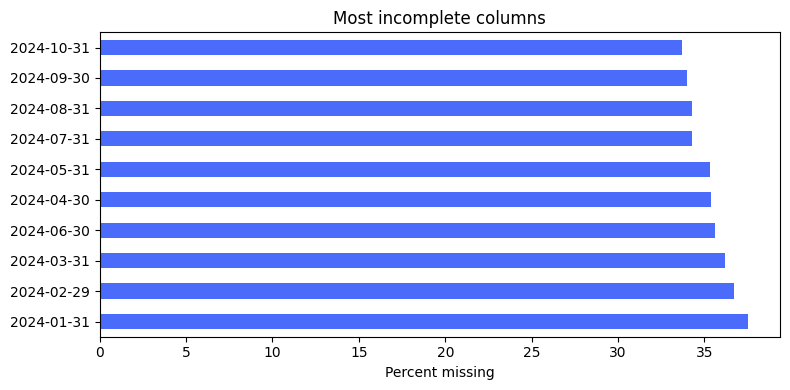

In [ ]:
missing = df.isna().sum().sort_values(ascending=False)
pct = (missing / len(df) * 100).round(1)
report = pd.DataFrame({"missing_count": missing, "percent_missing": pct})
display(report[report.missing_count > 0])

top = report[report.missing_count > 0].head(10)
if len(top):
  top.percent_missing.plot(kind="barh", figsize=(8,4), color="#4B6BFB")
  plt.xlabel("Percent missing"); plt.title("Most incomplete columns");plt.tight_layout(); plt.show()
else:
  print("No missing values found.")

#### 3. Uniqueness: Check for duplicates

In [ ]:
dupes = df.duplicated().sum()
print("Exact duplicate rows:", dupes, "which is", round(dupes/len(df)*100, 2), "percent")

for col in df.columns[:37]:
  n = df[col].nunique(dropna=True)
  print(f"{col:24} distinct values: {n}")

Exact duplicate rows: 0 which is 0.0 percent
RegionID                 distinct values: 638
SizeRank                 distinct values: 636
RegionName               distinct values: 638
RegionType               distinct values: 2
StateName                distinct values: 50
2024-01-31               distinct values: 399
2024-02-29               distinct values: 404
2024-03-31               distinct values: 407
2024-04-30               distinct values: 412
2024-05-31               distinct values: 413
2024-06-30               distinct values: 411
2024-07-31               distinct values: 419
2024-08-31               distinct values: 419
2024-09-30               distinct values: 421
2024-10-31               distinct values: 423
2024-11-30               distinct values: 426
2024-12-31               distinct values: 426
2025-01-31               distinct values: 439
2025-02-28               distinct values: 443
2025-03-31               distinct values: 452
2025-04-30               distinct valu

5. Validity: Check for values that sit outside a sensible range for errors, placeholder codes or unit mixups.

,count,mean,min,max
RegionID,638.0,413939.03,102001.00,845169.00
SizeRank,638.0,349.79,0.00,930.00
2024-01-31,399.0,1326.59,626.86,3130.01
2024-02-29,404.0,1324.54,637.02,3148.97
2024-03-31,407.0,1333.59,634.67,3177.35
2024-04-30,412.0,1336.23,628.79,3206.50
2024-05-31,413.0,1342.66,630.21,3238.02
2024-06-30,411.0,1351.61,631.02,3267.40
2024-07-31,419.0,1351.63,630.18,3284.38
2024-08-31,419.0,1355.61,626.91,3289.40


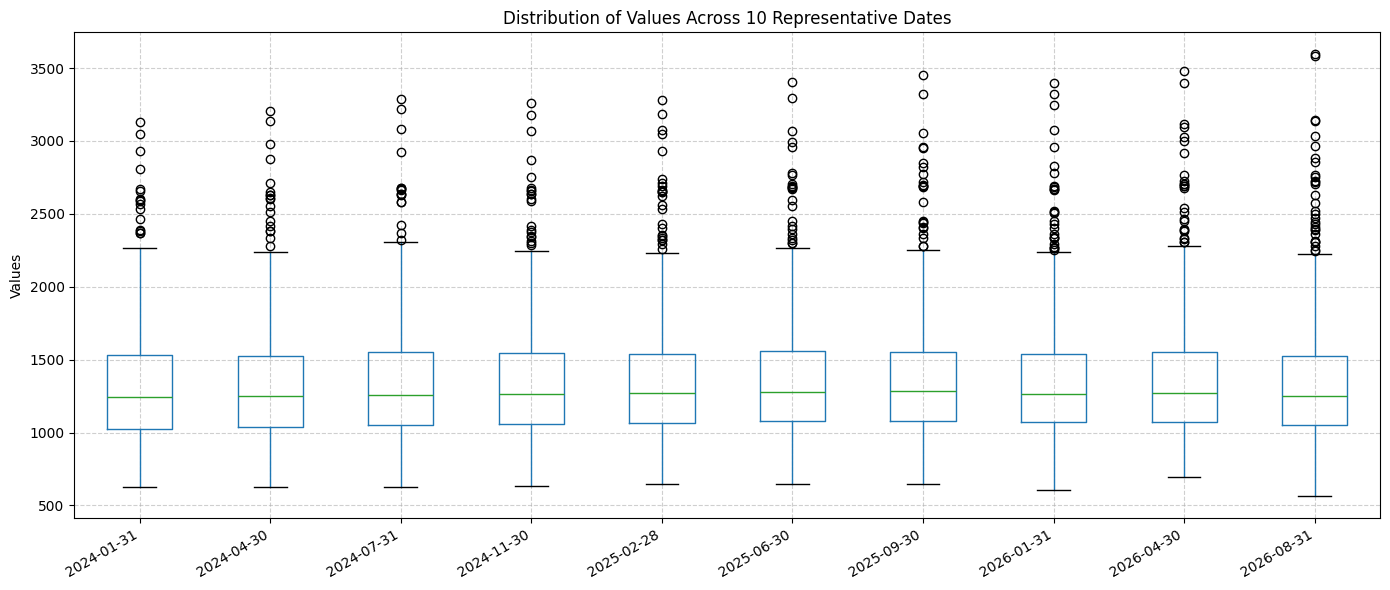

In [ ]:
nums = df.select_dtypes("number")
display(nums.describe().T[["count","mean","min","max"]].round(2))

# Filter numeric columns to a few representative date columns to prevent overcrowding
date_cols = [col for col in df.columns if col.match(r'\d{4}-\d{2}-\d{2}')] if hasattr(df.columns, 'match') else [c for c in df.columns if '-' in str(c)]

# Let's pick 10 representative dates spread across the timeline for a clean boxplot
if len(date_cols) >= 10:
    import numpy as np
    sample_indices = np.linspace(0, len(date_cols) - 1, 10, dtype=int)
    selected_cols = [date_cols[i] for i in sample_indices]

    plt.figure(figsize=(14, 6))
    df[selected_cols].boxplot()
    plt.title("Distribution of Values Across 10 Representative Dates")
    plt.ylabel("Values")
    plt.xticks(rotation=30, ha='right')
    plt.grid(True, linestyle='--', alpha=0.6)
    plt.tight_layout()
    plt.show()
else:
    print("Not enough temporal columns to plot 10 representative distributions.")

#### 4. Consistency: Check for inconsistent formats

In [ ]:
texts = df[[c for c in df.columns if df[c].dtype == object or str(df[c].dtype) in ("string", "category")]]
for col in texts.columns[:8]:
  vals = df[col].dropna().astype(str)
  raw = vals.nunique()
  cleaned = vals.str.strip().str.lower().nunique()
  flag = " <-- inconsistent formatting" if cleaned < raw else ""
  print(f"{col:24} as stored: {raw:5} ignoring case and spaces: {cleaned:5}{flag}")

RegionName               as stored:   638 ignoring case and spaces:   638
RegionType               as stored:     2 ignoring case and spaces:     2
StateName                as stored:    50 ignoring case and spaces:    50


#### 5. Representation: Check which data points are over represented

,rows,percent
StateName,,
TX,43,6.7
CA,32,5.0
OH,29,4.5
PA,28,4.4
NY,25,3.9
FL,24,3.8
NC,22,3.4
MI,22,3.4
GA,22,3.4


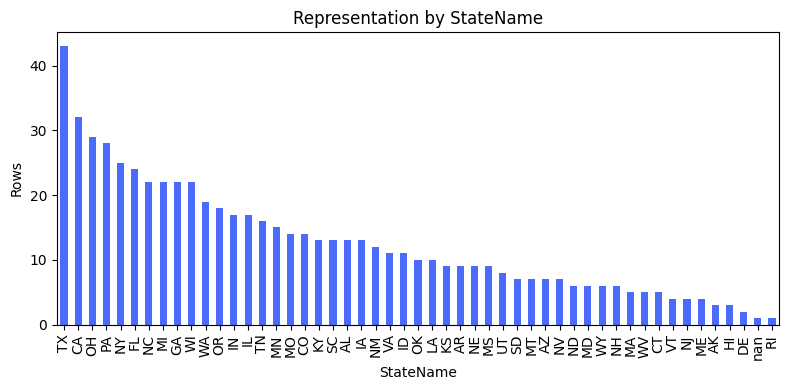

In [ ]:
GROUP_COLUMN = "StateName"     # change to a column that identifies a group in your dataset

counts = df[GROUP_COLUMN].value_counts(dropna=False)
share = (counts / counts.sum() * 100).round(1)
display(pd.DataFrame({"rows": counts, "percent": share}))

counts.plot(kind="bar", figsize=(8,4), color="#4B6BFB")
plt.ylabel("Rows"); plt.title(f"Representation by {GROUP_COLUMN}"); plt.tight_layout(); plt.show()

#### 6. Human Record Sampling
To perform a statistically rigorous yet operationally efficient quality audit, I selected a representative random sample of 60 records, which satisfies a standard 90% confidence level with a 10% margin of error for a total population of 638 regions.

In [ ]:
sampledf = df.sample(60, random_state=42)
display(sampledf)
print("Total missing values:", sampledf.isna().sum().sum())

,RegionID,SizeRank,RegionName,RegionType,StateName,2024-01-31,2024-02-29,2024-03-31,2024-04-30,2024-05-31,2024-06-30,2024-07-31,2024-08-31,2024-09-30,2024-10-31,2024-11-30,2024-12-31,2025-01-31,2025-02-28,2025-03-31,2025-04-30,2025-05-31,2025-06-30,2025-07-31,2025-08-31,2025-09-30,2025-10-31,2025-11-30,2025-12-31,2026-01-31,2026-02-28,2026-03-31,2026-04-30,2026-05-31,2026-06-30,2026-07-31,2026-08-31
260,395007,264,"Pueblo, CO",msa,CO,1127.684171,1129.739881,1135.296043,1136.639799,1143.355154,1152.701875,1156.021618,1151.663528,1128.014654,1131.622599,1133.630494,1136.941208,1122.328179,1127.444621,1146.762492,1163.337397,1162.013850,1171.157446,1180.347522,1188.637020,1184.032565,1171.888816,1167.906778,1165.512958,1162.916242,1161.939853,1160.093327,1165.952357,1176.798226,1182.152979,1174.482691,1164.650001
228,395011,231,"Racine, WI",msa,WI,1198.074483,1216.721327,1192.709899,1193.092815,1188.913861,1211.563085,1219.006818,1244.794903,1248.233567,1227.874023,1225.539797,1224.538452,1251.188691,1246.441070,1261.761429,1269.113849,1280.143703,1303.575091,1300.090515,1317.226934,1300.682606,1325.252100,1307.079319,1298.947970,1286.857939,1308.727928,1323.854238,1343.072605,1340.384314,1342.243633,1369.212363,1383.019201
31,394735,31,"Kansas City, MO",msa,MO,1258.200409,1261.886322,1267.969115,1277.857681,1291.490917,1303.824152,1311.423195,1312.827938,1306.898534,1301.591689,1294.181746,1294.961734,1304.021254,1315.727716,1326.575712,1334.896474,1340.134358,1347.246595,1349.994748,1352.084022,1348.760315,1341.680352,1339.583127,1340.795853,1344.499703,1348.775253,1355.251578,1365.091120,1375.872262,1381.429465,1387.358160,1388.840624
583,394881,703,"Moscow, ID",msa,ID,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,925.653376,951.193846,1005.786467,1025.851148,1016.846915,997.214140,967.449563,962.112332,959.029325,993.903628,991.598564,999.439487,988.368109,1011.868022,1047.928864,1047.889600,1027.602812,983.887262,987.356227,979.583333
600,395137,745,"Sulphur Springs, TX",msa,TX,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1232.000000
30,394775,30,"Las Vegas, NV",msa,NV,1497.925638,1498.655342,1501.792646,1513.262628,1528.077705,1538.141359,1536.261223,1531.217396,1522.895525,1515.280366,1507.240476,1503.133421,1508.645512,1516.288188,1526.255052,1528.662094,1530.940318,1528.355799,1527.040289,1521.807467,1512.777294,1509.528780,1503.689178,1504.427758,1503.039303,1507.507228,1510.757644,1513.525458,1516.557210,1518.816713,1513.678689,1508.336229
593,394771,733,"Laramie, WY",msa,WY,NaN,941.743647,940.685016,967.163257,967.756961,964.962234,967.204076,982.383672,971.934233,970.558554,977.066563,1007.998687,1006.460866,1005.101200,1001.852311,1030.927279,1036.877984,1044.464068,1039.238406,1035.478337,1015.446352,988.869861,980.561077,988.276055,1009.736653,1017.978906,1040.248835,1058.760290,1068.998996,1054.528121,1052.796327,1054.285185
110,394971,111,"Pensacola, FL",msa,FL,1514.381586,1523.875462,1528.467675,1520.035546,1532.106017,1538.781962,1550.924542,1552.479793,1555.050452,1542.814730,1521.497412,1501.114209,1503.348085,1519.803476,1531.105519,1536.811307,1541.122915,1544.872675,1551.919659,1549.647672,1550.622223,1546.980019,1548.352406,1547.080763,1549.849129,1549.908549,1562.476592,1569.919111,1580.704619,1584.157615,1593.366786,1591.618121
247,394299,251,"Abilene, TX",msa,TX,1019.398998,1017.516650,1004.748041,1005.624155,1011.222812,1018.633944,1030.624672,1043.424285,1068.892952,1069.834308,1078.931073,1063.194564,1070.419855,1070.008372,1092.910053,1116.163034,1156.149772,1189.778427,1227.328493,1278.400302,1331.139752,1363.451507,1404.076124,1434.442587,1467.900038,1497.352440,1509.716423,1582.457352,1652.213654,1736.409470,1749.651658,1691.571605
523,395204,578,"Warrensburg, MO",msa,MO,795.460002,804.253246,806.963333,817.586025,821.246971,830.688834,837.871393,839.203421,839.502213,837.443022,843.474359,841.338533,844.382116,843

Total missing values: 422


# **Completeness Evidence**

*   Missing values: 422 out of 1850
*   Missing rows: 22
*   Assessment: 77.19% Completeness Score - Fair
*   This indicates a notable amount of incomplete data that may impact reporting accuracy, analysis reliability, and downstream processes.

**Accuracy Evidence**
*   Incorrect values: 2 - geographic misalignment between RegionName and StateName
*   Extreme Values: 0
*   Out-of-Bound Rental Values: 0
*   Assessment: 96.7% Accuracy Score - Excellent
*   This indicates highly accurate data, reflecting no incorrect values.

**Consistency Evidence**
*   Timestamp: 100%
*   Schema Consistency: 100%
*   Logical Rent Scaling: 100%
*   Formatting Consistency: 100%
*   Assessment: 100% Consistency - Excellent
*   This indicates consistency across the dataset.

**Validity Evidence**
*   RegionID and SizeRank: consist only positive integer values
*   All rents fall within a realistic range
*   StateName values are valid with standard 2-letter US state postal abbreviatians
*   Assessment: 100% Valid Data

**Timeliness Evidence**
*   Data age: 32 months
*   Outdated records: No
*   Interval Frequency: 1 month
*   Assessment: Excellent - The data features rent values as recent as August 2026.

**Uniqeness Evidencess**
*   Duplcate RegionID records found: No
*   Duplicates between RegionName and StateName: No
*   Assessment: 100% Uniqueness - Excellent

**Representativeness Evidence**
*   Population coverage: Limited to US urban rental prices from 2024 to August 2026
*  Missing groups: International cities and rural US cities
*  Assessment: Representativeness is excellent for urban US rental rate trends. Its distribution ignores rural and international cities, but it is great for auditing regional market rents.

**Equity Assessment**
1.   **Representation and Demographic Coverage** - The ZORI heavily favors urban centers over rural and smaller communities. Some states, such as TX and CA, have more representation than others (like RI or DE). ZORI also relies on publicized online listing which excludes informal rental market, subsidized housing, and rentals filled via word-of-mouth or physical signage.
2.   **Historical & Geographic Equity** - Aggregating rents to the MSA level (e.g., "New York, NY" or "Los Angeles, CA") masks localized disparities. Systemic rent increases may disporportionately affect lower-income communities and flat increases affects a much high percentage of household income.
3.   **Missing Data Bias** - The completeness checks showed significal missing values across dates. If the missing data is concentrated in smaller, less affluent MSAs, removing these incomplete rows will systemically bias the dataset towards richer, larger cities with more stable data pipelines. If the missing values are imputes, using overall averages could artifically inflat or deflate the estimated rents of marginalized regions, leading to misleading business decisions.
4.   **Accessibility and Actionability of Insights** - A tool built on this dataset may help corporate developers or high-income renters find opportunities, but it may not serve local tenants or policy makers trying to address housing insecurity. The source data depends on internet-active landlords and tenants. If certain demographics are less active on online rental platforms, their markets remain invisibile in this dataset


